In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# === System Dynamics ===

def dynamics(x,u):
    x_dot = x[2, 0]
    y_dot = x[3, 0]
    
    f = u[0, 0]
    taf = u[1, 0]
    
    g = 9.81 # gravity
    m = 5.0 # body mass

    r = np.block([
        [x[0, 0]/np.sqrt(x[0, 0]**2 + x[1, 0]**2)], 
        [x[1, 0]/np.sqrt(x[0, 0]**2 + x[1, 0]**2)]
    ])

    x_vectord = np.block([
        [x_dot],
        [y_dot],
        [(r[0, 0]*f - r[1, 0]*taf)/m],
        [(r[1, 0]*f + r[0, 0]*taf)/m - g]
    ])

    return x_vectord

In [3]:
# === Euler Intergration ===

def euler(x, u, dt):
    x_n = x + dynamics(x, u) * dt
    
    return x_n

In [4]:
# === Runge-Kutta 4th Order integration ===

def rk4(x, u, dt):
    f1 = dynamics(x, u)
    f2 = dynamics(x + f1 * (dt/2), u)
    f3 = dynamics(x + f2 * (dt/2), u)
    f4 = dynamics(x + f3 * dt, u)
    x_n = x + (dt/6) * (f1 + 2*f2 + 2*f3 + f4)

    return x_n

In [ ]:
# === ALM Algorithm ===

def primal_dual_alm(Q, q, A, b, C, d, rho=10.0, epsilon_feas=1e-6, epsilon_stat=1e-6, max_iter=200):
    # Dimensions
    n = Q.shape[0]
    m_eq = A.shape[0] if A is not None else 0
    m_ineq = C.shape[0] if C is not None else 0

    # Initialization
    x = np.zeros((n, 1))
    s = np.maximum(d - C @ x, 0) if m_ineq > 0 else np.zeros((0, 1))
    lam = np.zeros((m_eq, 1)) if m_eq > 0 else np.zeros((0, 1))
    mu = np.zeros((m_ineq, 1)) if m_ineq > 0 else np.zeros((0, 1))

    prev_feas = np.inf

    for k in range(500):
        # Slack update
        if m_ineq > 0:
            s = np.maximum(d - C @ x - (1/rho) * mu, 0)

        # Primal update
        M = Q + rho * (A.T @ A + C.T @ C)
        rhs = -q - A.T @ (lam - rho * b) - C.T @ (mu - rho * (d - s))
        x = np.linalg.solve(M, rhs)

        # Dual updates
        if m_eq > 0:
            lam = lam + rho * (A @ x - b)
        if m_ineq > 0:
            mu = np.maximum(mu + rho * (C @ x + s - d), 0)

        # Check convergence
        feas_eq = np.linalg.norm(A @ x - b) if m_eq > 0 else 0
        feas_ineq = np.linalg.norm(C @ x + s - d) if m_ineq > 0 else 0
        stationarity = np.linalg.norm(Q @ x + q + A.T @ lam + C.T @ mu)

        if feas_eq < epsilon_feas and feas_ineq < epsilon_feas and stationarity < epsilon_stat:
            break

        # Penalty increase
        feas_res = max(feas_eq, feas_ineq)
        if abs(prev_feas - feas_res) / max(prev_feas, 1e-12) < 1e-3:
            rho *= 5
        prev_feas = feas_res

    return x, s, lam, mu



/tmp/ipykernel_1083/3852167928.py:43: RuntimeWarning: invalid value encountered in scalar divide
  if abs(prev_feas - feas_res) / max(prev_feas, 1e-12) < 1e-3:


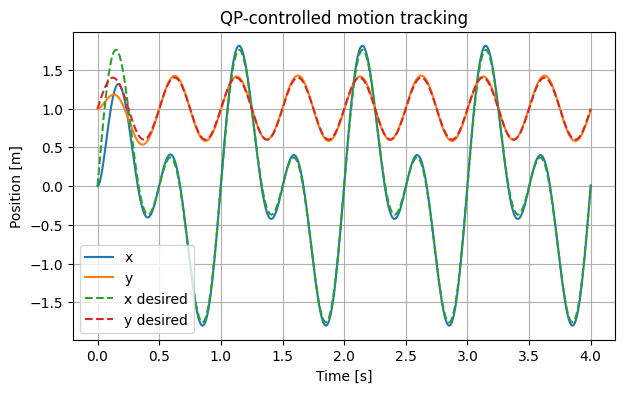

In [6]:
# === Simulation ===

dt = 0.01
T = 4.0
steps = int(T / dt)

x = np.array([[0.0], [1.0], [0.0], [0.0]])
x_hist = [x.flatten()]

# PD gains
Kp = np.diag([150, 80])
Kd = np.diag([18, 15])

# Reference trajectory parameters
Ax, Ay, omega = 0.5, 0.4, 2 * np.pi

u_prev = np.zeros((2, 1))

for t_i in range(steps):
    t = t_i * dt

    # Desired trajectory and derivatives
    xd = np.array([[np.sin(omega * t) + np.sin(2 * omega * t)], [1 + Ay * np.sin(2 * omega * t)]]) # +1 in y for plotting reasons
    xd_dot = np.array([[omega * (np.cos(omega * t) + 2 * np.cos(2 * omega * t))], [Ay * 2 * omega * np.cos(2 * omega * t)]])
    xd_ddot = np.array([[-omega**2 * (np.sin(omega * t) + 4 * np.sin(2 * omega * t))], [-Ay * (2 * omega)**2 * np.sin(2 * omega * t)]])

    # Current position and velocity
    pos = x[:2]
    vel = x[2:]

    # Desired acceleration with PD correction (PD correction optional, just better)
    acc_des = xd_ddot + Kp @ (xd - pos) + Kd @ (xd_dot - vel)

    # Build QP
    g = 9.81
    m = 5.0

    r = np.block([
        [x[0, 0]/np.sqrt(x[0, 0]**2 + x[1, 0]**2)], 
        [x[1, 0]/np.sqrt(x[0, 0]**2 + x[1, 0]**2)]
    ])
    r_x, r_y = r.flatten()

    A_qp = (1/m) * np.array([[r_x, -r_y],
                              [r_y,  r_x]])
    b_qp = acc_des + np.array([[0], [g]])
    
    Q = np.eye(2)
    q = -Q @ u_prev
    
    f_max = 10.0
    tau_max = 5.0

    C = np.array([[1, 0],[-1, 0],[0, 1],[0, -1]])
    d = np.array([[f_max],[0],[tau_max],[tau_max]])
    
    # Solve QP (no inequality constraints here)
    u_opt, _, _, _ = primal_dual_alm(Q, q, A_qp, b_qp, np.zeros((0, 2)), np.zeros((0, 1)))
    u_prev = u_opt

    # Integrate dynamics
    x = rk4(x, u_opt, dt)
    x_hist.append(x.flatten())

x_hist = np.array(x_hist)

# Plot results
t_vec = np.linspace(0, T, steps + 1)
plt.figure(figsize=(7,4))
plt.plot(t_vec, x_hist[:,0], label='x')
plt.plot(t_vec, x_hist[:,1], label='y')
plt.plot(t_vec, np.sin(omega * t_vec) + np.sin(2 * omega * t_vec), '--', label='x desired')
plt.plot(t_vec, 1 + Ay * np.sin(2*omega * t_vec), '--', label='y desired')
plt.legend()
plt.xlabel('Time [s]')
plt.ylabel('Position [m]')
plt.title('QP-controlled motion tracking')
plt.grid(True)
plt.show()


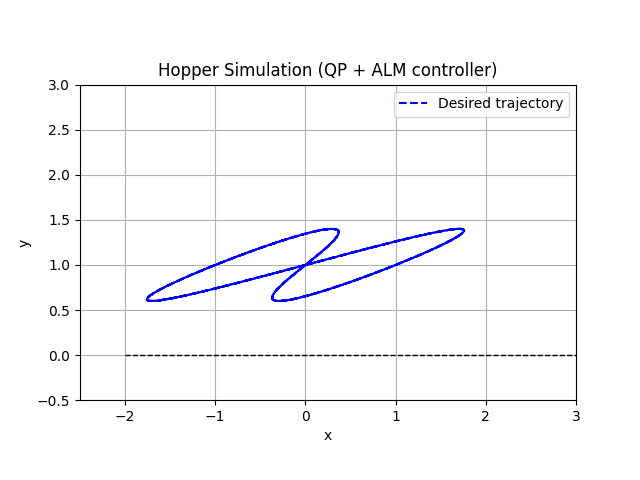

In [8]:
from matplotlib.animation import FuncAnimation
%matplotlib widget

# === Animation setup ===
fig, ax = plt.subplots()
ax.set_aspect('equal')
ax.set_xlim(-2.5, 3.0)
ax.set_ylim(-0.5, 3.0)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Hopper Simulation (QP + ALM controller)')
ax.grid(True)

# Static ground line
ax.plot([-2, 4], [0, 0], 'k--', lw=1)

# Dynamic elements (hopper rod + body)
rod_line, = ax.plot([], [], 'k-', lw=3)
mass_point = ax.scatter([], [], c='r', s=100)
trail, = ax.plot([], [], 'r:', lw=1)

# Desired trajectory
x_des = np.sin(omega * t_vec) + np.sin(2 * omega * t_vec)
y_des = 1 + Ay * np.sin(2 * omega * t_vec)
ax.plot(x_des, y_des, 'b--', label='Desired trajectory')
ax.legend()

# Initialize function
def init():
    rod_line.set_data([], [])
    mass_point.set_offsets(np.zeros((1, 2)))
    trail.set_data([], [])
    return (rod_line, mass_point, trail)

# Update function
def update(frame):
    x_current = x_hist[frame, 0]
    y_current = x_hist[frame, 1]
    
    # Draw the rod
    rod_line.set_data([0, x_current], [0, y_current])
    mass_point.set_offsets([x_current, y_current])
    
    # Trail of last few points
    trail_length = 50  # can be increased for longer trail
    start = max(0, frame - trail_length)
    trail.set_data(x_hist[start:frame, 0], x_hist[start:frame, 1])
    
    return (rod_line, mass_point, trail)

ani = FuncAnimation(fig, update, frames=len(x_hist), init_func=init, interval=20, blit=True, repeat=False)
plt.show()
